In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.datasets import load_iris

In [3]:
iris = load_iris()

In [4]:
iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [5]:
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)

In [6]:
df.head(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2


In [7]:
df['species']=iris.target

In [8]:
df.head(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0


In [9]:
df.columns = ['sp','sw', 'pl', 'pw', 'species']

In [10]:
df.head(2)

,sp,sw,pl,pw,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0


In [11]:
df = df[['sw', 'pl', 'species']]

In [12]:
df.head(2)

,sw,pl,species
0,3.5,1.4,0
1,3.0,1.4,0


In [14]:
mask = df['species']!=0

In [16]:
df = df[mask]

In [17]:
df.shape

(100, 3)

In [20]:
df.sample(5)

,sw,pl,species
121,2.8,4.9,2
87,2.3,4.4,1
119,2.2,5.0,2
100,3.3,6.0,2
83,2.7,5.1,1


In [21]:
df = df.sample(100)

In [22]:
df_train = df.iloc[:60, :].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:, :].sample(5)

In [39]:
df_train

,sw,pl,species
104,3.0,5.8,2
64,2.9,3.6,1
94,2.7,4.2,1
79,2.6,3.5,1
119,2.2,5.0,2
77,3.0,5.0,1
51,3.2,4.5,1
88,3.0,4.1,1
97,2.9,4.3,1
69,2.5,3.9,1


In [41]:
df_train['species'].value_counts()

species
1    8
2    2
Name: count, dtype: int64

In [23]:
X_test = df_val.iloc[:, 0:2].values

In [24]:
y_test = df_val.iloc[:, -1].values

In [25]:
X_test

array([[2.7, 3.9],
       [3.3, 4.7],
       [3.3, 5.7],
       [3.4, 4.5],
       [3. , 6.6]])

In [26]:
y_test

array([1, 1, 2, 1, 2])

In [27]:
df_bag = df_train.sample(8, replace=True)
X=df_bag.iloc[:, 0:2]
y=df_bag.iloc[:, -1]
df_bag

,sw,pl,species
88,3.0,4.1,1
94,2.7,4.2,1
69,2.5,3.9,1
64,2.9,3.6,1
97,2.9,4.3,1
94,2.7,4.2,1
88,3.0,4.1,1
51,3.2,4.5,1


In [31]:
!pip install mlxtend

In [33]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score 

In [34]:
dt_bag1 = DecisionTreeClassifier()

In [35]:
def evaluate(clf, X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf = clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_pred, y_pred))

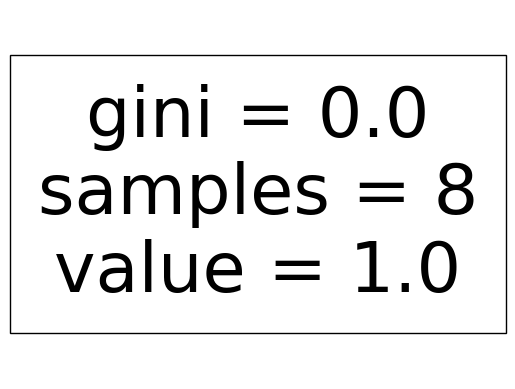

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\dell\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


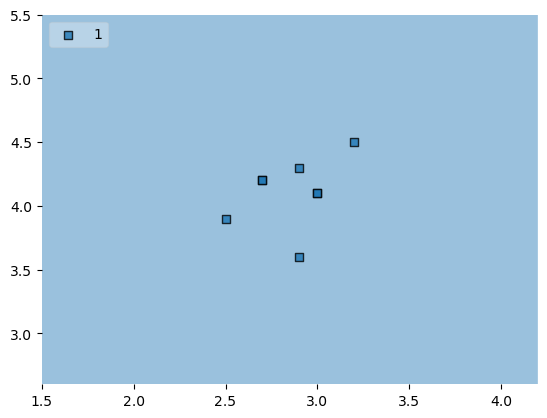

In [36]:
evaluate(dt_bag1, X,y)

In [37]:
df_bag = df_train.sample(8, replace=True)
X=df_bag.iloc[:, 0:2]
y=df_bag.iloc[:, -1]

,sw,pl,species
97,2.9,4.3,1
69,2.5,3.9,1
79,2.6,3.5,1
94,2.7,4.2,1
69,2.5,3.9,1
51,3.2,4.5,1
64,2.9,3.6,1
51,3.2,4.5,1


In [42]:
df_bag['species'].value_counts()

species
1    8
Name: count, dtype: int64

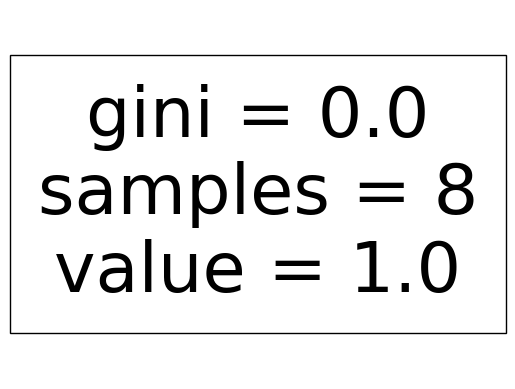

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\dell\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


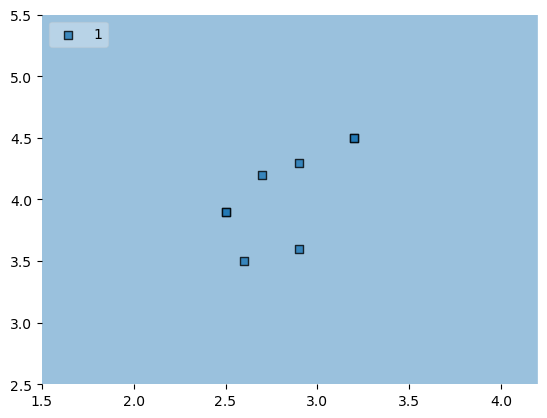

In [43]:
evaluate(dt_bag1, X,y)

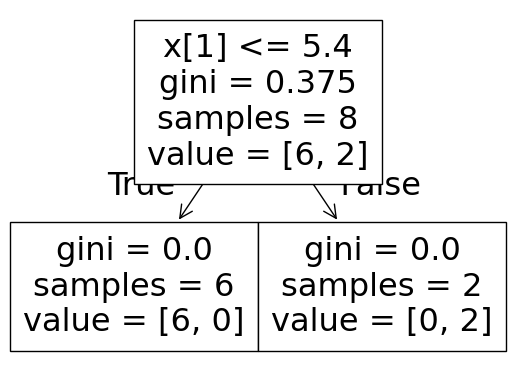

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\dell\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


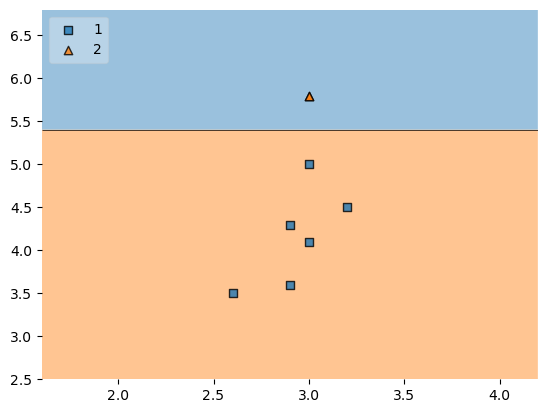

In [45]:
df_bag = df_train.sample(8, replace=True)
X=df_bag.iloc[:, 0:2]
y=df_bag.iloc[:, -1]
evaluate(dt_bag1, X,y)

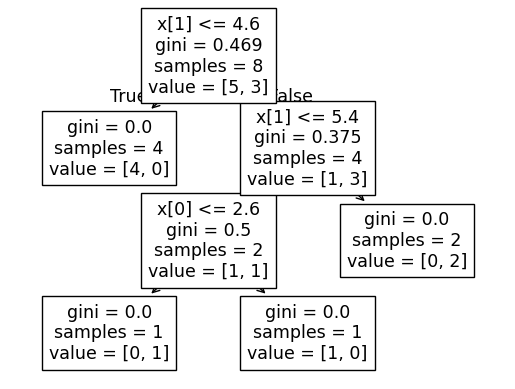

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\dell\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


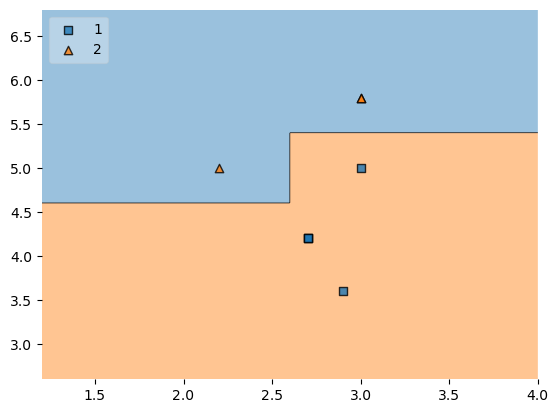

In [46]:
df_bag = df_train.sample(8, replace=True)
X=df_bag.iloc[:, 0:2]
y=df_bag.iloc[:, -1]
evaluate(dt_bag1, X,y)

## Pasting = We do row sampling but without replacement

## In Random Subspaces we do column sampling here

## Random Patches we combine Pasting and random subspaces